# Part 3 of 4: Business analysis of Hyderabad wedding venues

**Input:** `wedmegood_clean.csv` (from Part 2)

**Main price:** rental cost per function (the flat price of the venue; food, decor and services are extra). **Second price:** price per plate.

## The business questions

| # | Question | Who needs the answer |
|---|---|---|
| 1 | What is a normal rental cost, and how wide is the range? | Customers, owners |
| 2 | What size of wedding do venues cater to? | Customers, platform |
| 3 | Which venue types and areas have the most supply? | Platform, owners |
| 4 | How do venues show their price (per function, per plate, both, none)? | Customers, platform |
| 5 | Can customers trust ratings? | Customers, platform |
| 6 | How much does venue type change the rental cost? | Customers, owners |
| 7 | Which areas are cheaper or dearer? | Customers, owners |
| 8 | Does a bigger venue cost more, and which type gives the most space for the money? | Customers, owners |
| 9 | Do venues with rooms charge more (after comparing similar sizes)? | Owners |
| 10 | Do higher-rated venues charge more? | Owners, customers |
| 11 | Are promoted venues priced or rated differently? | Platform, customers |
| 12 | Which venue types show a flat rental cost and which show only a plate price? | Platform, customers |
| 13 | What is a fair price for my venue type and size? | Owners |
| 14 | What do high-priced venues offer that cheap ones do not? | Owners, customers |
| 15 | Where is supply thin (price and size combinations with few venues)? | Platform, owners |
| 16 | Which venues look like good value? | Customers |

Every chart is followed by a short **Insight** printed from the real data, so the numbers always match the chart.

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 90 ## Set the default resolution of plots to 90 DPI

df = pd.read_csv("wedmegood_clean.csv")
if df["rental_cost"].notna().sum() < 10:
    raise SystemExit("STOP: fewer than 10 venues have a rental cost in wedmegood_clean.csv. Re-run Parts 1 and 2 first.")

# Yes/No columns come back from the file as True/False
for col in ["is_paid", "has_rental_cost", "has_rooms", "enough_reviews"]:
    df[col] = df[col].fillna(False).astype(bool)

# Put the grouped columns back in their natural order
ORDER = {
    "rental_tier": ["Low", "Mid", "High"],
    "capacity_group": ["Up to 500", "501-1000", "1001-3000", "Above 3000"],
    "rating_group": ["Below 4.5", "4.5 to 4.9", "5.0"],
    "review_group": ["0", "1", "2 to 4", "5 to 9", "10+"],
}
for col, cats in ORDER.items():
    df[col] = pd.Categorical(df[col].astype(str), categories=cats, ordered=True)


def rs(x):
    """Format a number as rupees, for example 150000 -> ₹150,000"""
    return f"₹{x:,.0f}"


def count_in_order(series, order):
    """Count how many venues are in each group, in the order given (zero if a group is empty)."""
    s = series.astype(object)
    return pd.Series({k: int((s == k).sum()) for k in order})


print(f"Loaded {len(df)} venues and {df.shape[1]} columns.")

Loaded 500 venues and 29 columns.


In [15]:
df

,venue_name,detail_url,page,rating,reviews,area,venue_type_raw,venue_group,space_type,veg_price,...,capacity_min,capacity_max,rooms,has_rooms,extra_features,rental_tier,capacity_group,rating_group,cost_per_guest,log_capacity
0,Advaya Convention,https://www.wedmegood.com/wedding-venues/Advay...,1,5.0,7,Medchal,Large Lawn with Banquet,Banquet & Lawn,NaN,NaN,...,500.0,10000.0,8.0,True,3,NaN,Above 3000,5.0,NaN,4.000000
1,RajKamal Palace,https://www.wedmegood.com/wedding-venues/RajKa...,1,5.0,49,Kompally,European-Style Lawn,Lawn,NaN,NaN,...,250.0,500.0,2.0,True,7,NaN,Up to 500,5.0,NaN,2.698970
2,Arden Lakefront,https://www.wedmegood.com/wedding-venues/Arden...,1,5.0,3,NaN,Lake View/River View,Other,NaN,NaN,...,100.0,500.0,4.0,True,4,Mid,Up to 500,5.0,250.000000,2.698970
3,Anamkara Resort by Mrugavani,https://www.wedmegood.com/wedding-venues/Anamk...,1,5.0,1,NaN,Medak Mountain View Venue,Other,NaN,1300.0,...,20.0,1500.0,40.0,True,4,Mid,1001-3000,5.0,66.666667,3.176091
4,Dream Valley Resorts,https://www.wedmegood.com/wedding-venues/Dream...,1,4.2,11,Moinabad,Lush Wedding Resort,Resort,NaN,2000.0,...,100.0,5000.0,90.0,True,3,NaN,Above 3000,Below 4.5,NaN,3.698970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,Kothaapu Narsimha Reddy Banquet & Conference Hall,https://www.wedmegood.com/wedding-venues/Kotha...,26,NaN,0,Champapet,Banquet Hall,Banquet Hall,Indoor,400.0,...,300.0,400.0,NaN,False,2,NaN,Up to 500,NaN,NaN,2.602060
496,Baddam Surender Reddy,https://www.wedmegood.com/wedding-venues/Badda...,26,NaN,0,NaN,Convention Hall & Lawn,Convention Hall,Indoor & Outdoor,NaN,...,1500.0,2250.0,NaN,False,3,Mid,1001-3000,NaN,44.444444,3.352183
497,Hotel Suprabhat,https://www.wedmegood.com/wedding-venues/Hotel...,26,5.0,3,Tarnaka,Banquet Hall,Banquet Hall,Indoor,350.0,...,250.0,350.0,NaN,False,2,NaN,Up to 500,5.0,NaN,2.544068
498,Habeeb Function Hall,https://www.wedmegood.com/wedding-venues/Habee...,26,NaN,0,Falaknuma,Banquet Hall,Banquet Hall,Indoor,NaN,...,250.0,400.0,NaN,False,2,NaN,Up to 500,NaN,NaN,2.602060


In [13]:
df.columns

Index(['venue_name', 'detail_url', 'page', 'rating', 'reviews', 'area',
       'venue_type_raw', 'venue_group', 'space_type', 'veg_price',
       'nonveg_price', 'rental_cost', 'pricing_type', 'has_rental_cost',
       'capacity_min', 'capacity_max', 'rooms', 'has_rooms', 'extra_features',
       'rental_tier', 'capacity_group', 'rating_group', 'cost_per_guest',
       'log_capacity'],
      dtype='str')

# A. One variable at a time

### Q1. What is a normal rental cost, and how wide is the range?

119 of 421 venues (28%) show a rental cost per function.

count        119.0
mean      220126.0
std       383563.0
min         3500.0
25%        45000.0
50%        94000.0
75%       260000.0
max      3500000.0


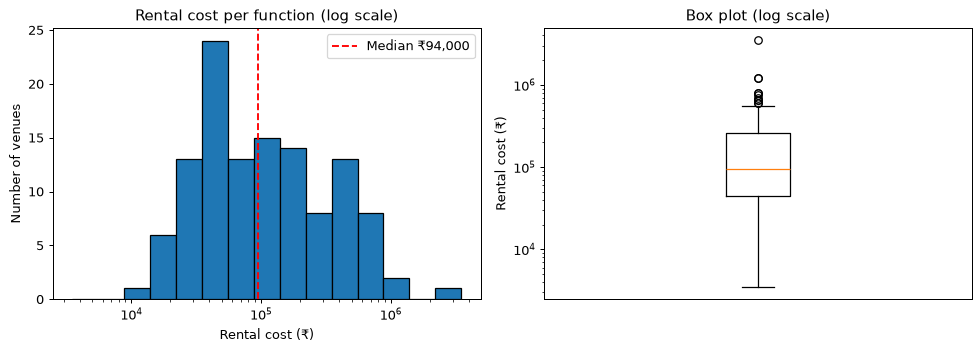

INSIGHT
- The typical (median) rental cost is ₹94,000. The middle half of venues charge ₹45,000 to ₹260,000.
- The cheapest is ₹3,500 and the dearest ₹3,500,000, about 1000 times more.
- The mean (₹220,126) is above the median, so a few expensive venues pull the average up. Use the median as the 'normal price'.
- One venue in 10 charges more than ₹510,000.


In [2]:
cost = df["rental_cost"].dropna()
print(f"{len(cost)} of {len(df)} venues ({len(cost) / len(df):.0%}) show a rental cost per function.\n")
print(cost.describe().round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.logspace(np.log10(cost.min()), np.log10(cost.max()), 16)
axes[0].hist(cost, bins=bins, edgecolor="black") #axes contains the individual plotting areas.
axes[0].set_xscale("log")
axes[0].axvline(cost.median(), color="red", linestyle="--", label=f"Median {rs(cost.median())}")
axes[0].set_title("Rental cost per function (log scale)")
axes[0].set_xlabel("Rental cost (₹)")
axes[0].set_ylabel("Number of venues")
axes[0].legend()
axes[1].boxplot(cost)
axes[1].set_yscale("log")
axes[1].set_xticks([])
axes[1].set_title("Box plot (log scale)")
axes[1].set_ylabel("Rental cost (₹)")
plt.tight_layout()
plt.show()

print("INSIGHT")
print(f"- The typical (median) rental cost is {rs(cost.median())}. The middle half of venues charge {rs(cost.quantile(0.25))} to {rs(cost.quantile(0.75))}.")
print(f"- The cheapest is {rs(cost.min())} and the dearest {rs(cost.max())}, about {cost.max() / cost.min():.0f} times more.")
if cost.mean() > cost.median():
    print(f"- The mean ({rs(cost.mean())}) is above the median, so a few expensive venues pull the average up. Use the median as the 'normal price'.")
print(f"- One venue in 10 charges more than {rs(cost.quantile(0.9))}.")

**How to use this:** Customers can use the median as the starting budget for the venue alone (food and decor come on top). Owners near the median are in the safe zone; going well above needs a visible reason. The platform should offer price filters with sensible steps.

### Q2. What size of wedding do venues cater to?

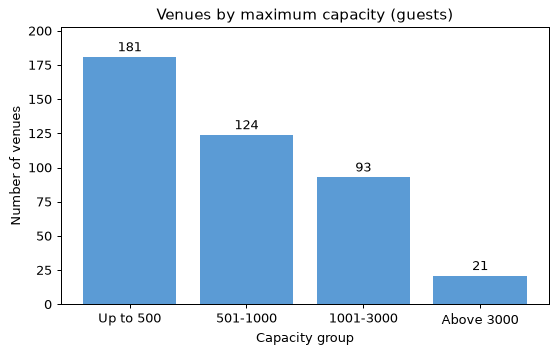

INSIGHT
- The typical venue holds up to 600 guests. The largest holds 10,000.
- 73% of venues hold up to 1,000 guests; 21 venues hold more than 3,000.
- Most common size group: 'Up to 500' (181 venues).


In [3]:
cap = df["capacity_max"].dropna()
cap_counts = count_in_order(df["capacity_group"], ORDER["capacity_group"])

plt.figure(figsize=(7, 4))
bars = plt.bar(cap_counts.index, cap_counts.values, color="#5b9bd5")
plt.bar_label(bars, padding=2)
plt.margins(y=0.12)
plt.title("Venues by maximum capacity (guests)")
plt.xlabel("Capacity group")
plt.ylabel("Number of venues")
plt.show()

print("INSIGHT")
print(f"- The typical venue holds up to {cap.median():,.0f} guests. The largest holds {cap.max():,.0f}.")
print(f"- {(cap <= 1000).mean():.0%} of venues hold up to 1,000 guests; {int((cap > 3000).sum())} venues hold more than 3,000.")
print(f"- Most common size group: '{cap_counts.idxmax()}' ({cap_counts.max()} venues).")

**How to use this:** Guest count is the first filter a customer should use. Very large venues are few, so big weddings should book early. For owners, a very large venue is a niche with less competition but fewer customers.

### Q3. Which venue types and areas have the most supply?

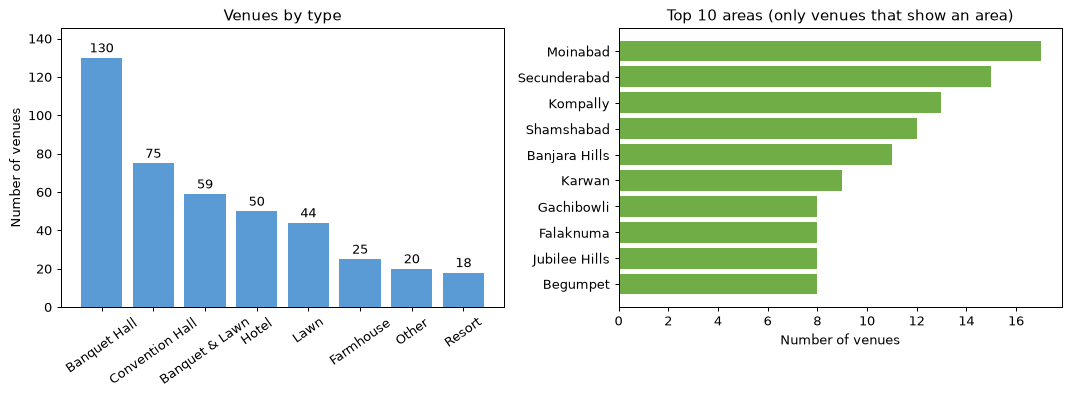

INSIGHT
- 'Banquet Hall' (130) and 'Convention Hall' (75) are the two biggest types: 49% of all venues.
- Fewest listings: 'Resort' with 18 venue(s). Types with few listings are where the platform could add venues.
- 276 of 421 venues show an area; they are spread over 74 areas.
- The top 5 areas hold 25% of the venues that show an area.
- 17 areas have only one venue.


In [4]:
type_counts = df["venue_group"].value_counts()
area_counts = df["area"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bars = axes[0].bar(type_counts.index, type_counts.values, color="#5b9bd5")
axes[0].bar_label(bars, padding=2)
axes[0].margins(y=0.12)
axes[0].set_title("Venues by type")
axes[0].tick_params(axis="x", rotation=35)
axes[0].set_ylabel("Number of venues")
if len(area_counts) > 0:
    top = area_counts.head(10).sort_values()
    axes[1].barh(top.index, top.values, color="#70ad47")
    axes[1].set_title("Top 10 areas (only venues that show an area)")
    axes[1].set_xlabel("Number of venues")
else:
    axes[1].text(0.5, 0.5, "No area information", ha="center")
plt.tight_layout()
plt.show()

print("INSIGHT")
if len(type_counts) >= 2:
    two = type_counts.head(2)
    print(f"- '{two.index[0]}' ({two.iloc[0]}) and '{two.index[1]}' ({two.iloc[1]}) are the two biggest types: {two.sum() / len(df):.0%} of all venues.")
print(f"- Fewest listings: '{type_counts.index[-1]}' with {type_counts.iloc[-1]} venue(s). Types with few listings are where the platform could add venues.")
if len(area_counts) > 0:
    print(f"- {df['area'].notna().sum()} of {len(df)} venues show an area; they are spread over {len(area_counts)} areas.")
    print(f"- The top 5 areas hold {area_counts.head(5).sum() / area_counts.sum():.0%} of the venues that show an area.")
    print(f"- {int((area_counts == 1).sum())} areas have only one venue.")

**How to use this:** In crowded types and areas, owners compete on price and facilities. In thin ones, customers have little to compare. Venues with no area are hard to find by location, so the platform should ask every venue for its area.

### Q4. How do venues show their price?

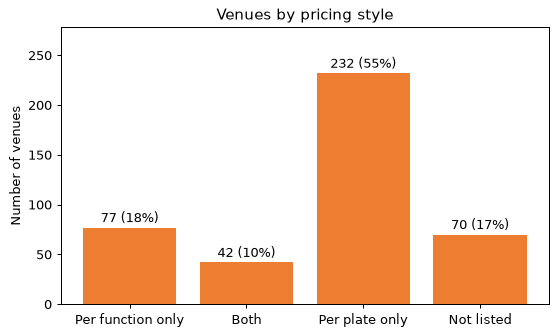

INSIGHT
- Per function only: 77 venues (18%)
- Both: 42 venues (10%)
- Per plate only: 232 venues (55%)
- Not listed: 70 venues (17%)
- Veg plate price: 273 venues, median ₹500, middle half ₹360 to ₹800.


In [5]:
style_order = ["Per function only", "Both", "Per plate only", "Not listed"]
style_counts = count_in_order(df["pricing_type"], style_order)

plt.figure(figsize=(7, 4))
bars = plt.bar(style_counts.index, style_counts.values, color="#ed7d31")
plt.bar_label(bars, labels=[f"{v} ({v / len(df):.0%})" for v in style_counts.values], padding=2)
plt.title("Venues by pricing style")
plt.ylabel("Number of venues")
plt.ylim(0, style_counts.max() * 1.2)
plt.show()

print("INSIGHT")
for style, n in style_counts.items():
    print(f"- {style}: {n} venues ({n / len(df):.0%})")
veg = df["veg_price"].dropna()
if len(veg) > 0:
    print(f"- Veg plate price: {len(veg)} venues, median {rs(veg.median())}, middle half {rs(veg.quantile(0.25))} to {rs(veg.quantile(0.75))}.")

**How to use this:** A flat rental cost and a plate price cannot be compared directly. For a plate-only venue, ask for the rental cost and the minimum guest guarantee. The platform should show both prices in one clear format.

### Q5. Can customers trust ratings?

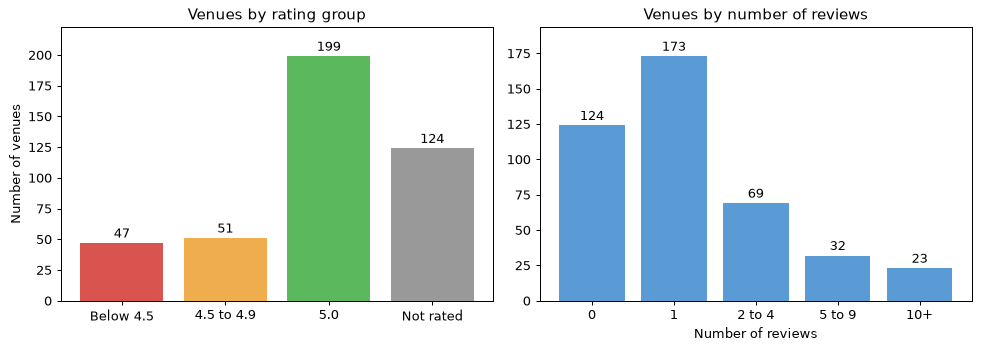

INSIGHT
- 297 of 421 venues have a rating. The average is 4.76 and the lowest is 0.5.
- 67% of rated venues have a perfect 5.0.
- The median venue has 1 review(s); 87% of venues have fewer than 5 reviews.
- 84% of ratings are 4.5 or higher and 87% of venues have fewer than 5 reviews, so a rating alone cannot separate venues.


In [6]:
rating_labels = df["rating_group"].astype(object).fillna("Not rated")
rating_counts = count_in_order(rating_labels, ORDER["rating_group"] + ["Not rated"])
review_counts = count_in_order(df["review_group"], ORDER["review_group"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar(rating_counts.index, rating_counts.values, color=["#d9534f", "#f0ad4e", "#5cb85c", "#999999"])
axes[0].bar_label(bars, padding=2)
axes[0].margins(y=0.12)
axes[0].set_title("Venues by rating group")
axes[0].set_ylabel("Number of venues")
bars = axes[1].bar(review_counts.index, review_counts.values, color="#5b9bd5")
axes[1].bar_label(bars, padding=2)
axes[1].margins(y=0.12)
axes[1].set_title("Venues by number of reviews")
axes[1].set_xlabel("Number of reviews")
plt.tight_layout()
plt.show()

rated = df["rating"].dropna()
print("INSIGHT")
if len(rated) > 0:
    print(f"- {len(rated)} of {len(df)} venues have a rating. The average is {rated.mean():.2f} and the lowest is {rated.min():.1f}.")
    print(f"- {(rated == 5.0).mean():.0%} of rated venues have a perfect 5.0.")
print(f"- The median venue has {df['reviews'].median():.0f} review(s); {(df['reviews'] < 5).mean():.0%} of venues have fewer than 5 reviews.")
top_share = (rated >= 4.5).mean() if len(rated) > 0 else 0
few_share = (df["reviews"] < 5).mean()
if top_share >= 0.7 and few_share >= 0.5:
    print(f"- {top_share:.0%} of ratings are 4.5 or higher and {few_share:.0%} of venues have fewer than 5 reviews, so a rating alone cannot separate venues.")
elif top_share >= 0.7:
    print(f"- {top_share:.0%} of ratings are 4.5 or higher, so ratings sit near the top and do not separate venues well.")
else:
    print(f"- Ratings are spread out more ({top_share:.0%} are 4.5 or higher), so they do help to tell venues apart.")

**How to use this:** Customers should read the review count together with the rating. Owners can build trust cheaply by asking recent customers for reviews. The platform could show the rating only after a minimum number of reviews.

# B. Two variables together

### Q6. How much does venue type change the rental cost?
Only types with at least 5 priced venues are charted.

                 venues  priced  median_cost  median_capacity
venue_group                                                  
Convention Hall      75      27     350000.0           1500.0
Other                19       4     200000.0            450.0
Resort               18       4     187500.0           1500.0
Banquet & Lawn       59      22     162500.0            700.0
Lawn                 44      21      70000.0            600.0
Banquet Hall        130      23      60000.0            400.0
Farmhouse            25      14      60000.0            200.0
Hotel                50       4      22500.0            500.0



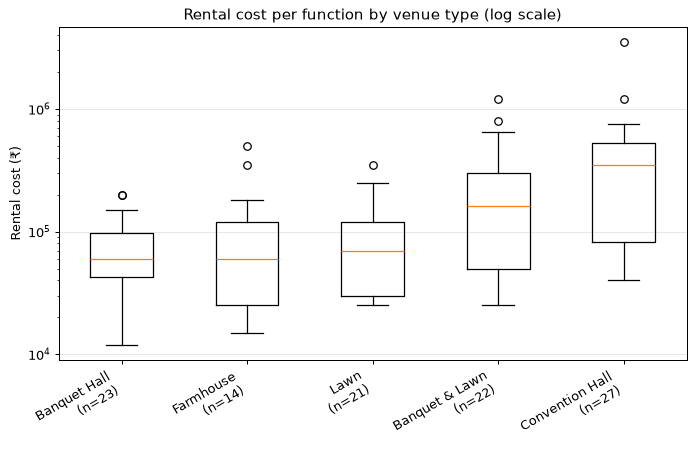

INSIGHT
- Highest median: 'Convention Hall' at ₹350,000. Lowest: 'Banquet Hall' at ₹60,000.
- The dearest type costs about 5.8 times the cheapest.


In [7]:
type_cost = df.groupby("venue_group").agg(
    venues=("venue_name", "count"),
    priced=("rental_cost", "count"),
    median_cost=("rental_cost", "median"),
    median_capacity=("capacity_max", "median"),
).sort_values("median_cost", ascending=False)
print(type_cost.round(0).to_string())

enough = type_cost[type_cost["priced"] >= 5].sort_values("median_cost")
print()
if len(enough) >= 2:
    names = list(enough.index)
    data = [df.loc[df["venue_group"] == t, "rental_cost"].dropna() for t in names]
    plt.figure(figsize=(9, 4.8))
    plt.boxplot(data)
    plt.xticks(range(1, len(names) + 1), [f"{t}\n(n={len(d)})" for t, d in zip(names, data)], rotation=30, ha="right")
    plt.yscale("log")
    plt.title("Rental cost per function by venue type (log scale)")
    plt.ylabel("Rental cost (₹)")
    plt.grid(axis="y", alpha=0.3)
    plt.show()
    print("INSIGHT")
    print(f"- Highest median: '{enough.index[-1]}' at {rs(enough['median_cost'].iloc[-1])}. Lowest: '{enough.index[0]}' at {rs(enough['median_cost'].iloc[0])}.")
    print(f"- The dearest type costs about {enough['median_cost'].iloc[-1] / enough['median_cost'].iloc[0]:.1f} times the cheapest.")
else:
    print("Fewer than 2 venue types have 5 or more priced venues, so no chart is drawn.")

**How to use this:** Venue type is a quick way for customers to set a budget. An owner priced above the median of their type should support it with something visible: capacity, rooms or strong reviews.

### Q7. Which areas are cheaper or dearer?
Only areas with at least 3 priced venues are used, so one venue does not decide an area.

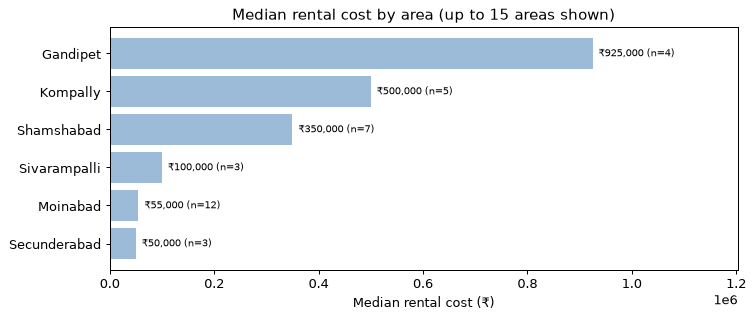

INSIGHT
- 6 areas have at least 3 priced venues.
- Dearest: Gandipet (₹925,000). Cheapest: Secunderabad (₹50,000).
- Each area has only a few priced venues, so treat these as hints, not firm rankings.


In [8]:
area_cost = df[df["area"].notna()].groupby("area").agg(
    venues=("venue_name", "count"),
    priced=("rental_cost", "count"),
    median_cost=("rental_cost", "median"),
)
area_cost = area_cost[area_cost["priced"] >= 3].sort_values("median_cost")

if len(area_cost) >= 2:
    shown = area_cost.tail(15)
    plt.figure(figsize=(9, max(3.5, len(shown) * 0.35)))
    plt.barh(shown.index, shown["median_cost"], color="#9bbbd9")
    for y, (value, n) in enumerate(zip(shown["median_cost"], shown["priced"])):
        plt.text(value, y, f"  {rs(value)} (n={n})", va="center", fontsize=8)
    plt.xlim(0, shown["median_cost"].max() * 1.3)
    plt.title("Median rental cost by area (up to 15 areas shown)")
    plt.xlabel("Median rental cost (₹)")
    plt.show()
    print("INSIGHT")
    print(f"- {len(area_cost)} areas have at least 3 priced venues.")
    print(f"- Dearest: {area_cost.index[-1]} ({rs(area_cost['median_cost'].iloc[-1])}). Cheapest: {area_cost.index[0]} ({rs(area_cost['median_cost'].iloc[0])}).")
    print("- Each area has only a few priced venues, so treat these as hints, not firm rankings.")
else:
    print("Fewer than 2 areas have 3 or more priced venues, so no area comparison is possible with this data.")

**How to use this:** On a tight budget, compare nearby areas: a cheaper neighbouring area can give a similar venue for less. Owners should compare their price with their own area before changing it.

### Q8. Does a bigger venue cost more, and which type gives the most space for the money?

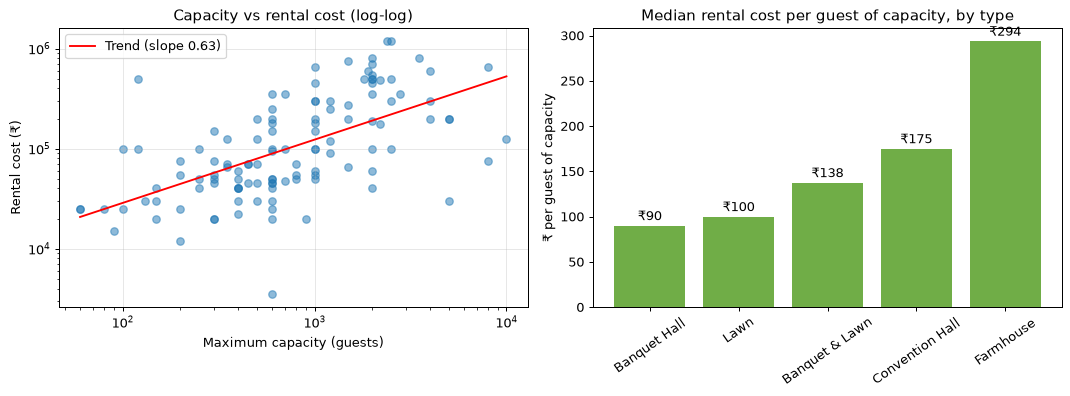

INSIGHT
- Capacity and rental cost have a strong link (Spearman 0.64, 118 venues).
- On the trend line, a venue with 10% more capacity costs about 6.2% more.
- Most space for the money: 'Banquet Hall' (₹90 per guest). Least: 'Farmhouse' (₹294).


In [9]:
pair = df[["capacity_max", "rental_cost"]].dropna()
rho = pair.corr(method="spearman").iloc[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(pair["capacity_max"], pair["rental_cost"], alpha=0.5)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
slope = None
if len(pair) >= 10 and pair["capacity_max"].nunique() > 1:
    slope, intercept = np.polyfit(np.log10(pair["capacity_max"]), np.log10(pair["rental_cost"]), 1)
    xs = np.linspace(pair["capacity_max"].min(), pair["capacity_max"].max(), 100)
    axes[0].plot(xs, 10 ** (intercept + slope * np.log10(xs)), color="red", label=f"Trend (slope {slope:.2f})")
    axes[0].legend()
axes[0].set_title("Capacity vs rental cost (log-log)")
axes[0].set_xlabel("Maximum capacity (guests)")
axes[0].set_ylabel("Rental cost (₹)")
axes[0].grid(alpha=0.3)

cpg = df.groupby("venue_group").agg(n=("cost_per_guest", "count"), median_cpg=("cost_per_guest", "median"))
cpg = cpg[cpg["n"] >= 5].sort_values("median_cpg")
if len(cpg) > 0:
    bars = axes[1].bar(cpg.index, cpg["median_cpg"], color="#70ad47")
    axes[1].bar_label(bars, labels=[f"₹{v:,.0f}" for v in cpg["median_cpg"]], padding=2)
    axes[1].tick_params(axis="x", rotation=35)
    axes[1].set_title("Median rental cost per guest of capacity, by type")
    axes[1].set_ylabel("₹ per guest of capacity")
else:
    axes[1].text(0.5, 0.5, "Not enough data", ha="center")
plt.tight_layout()
plt.show()

strength = "strong" if abs(rho) >= 0.6 else "moderate" if abs(rho) >= 0.3 else "weak"
print("INSIGHT")
print(f"- Capacity and rental cost have a {strength} link (Spearman {rho:.2f}, {len(pair)} venues).")
if slope is not None:
    print(f"- On the trend line, a venue with 10% more capacity costs about {(1.1 ** slope - 1) * 100:.1f}% more.")
if len(cpg) > 0:
    print(f"- Most space for the money: '{cpg.index[0]}' (₹{cpg['median_cpg'].iloc[0]:,.0f} per guest). Least: '{cpg.index[-1]}' (₹{cpg['median_cpg'].iloc[-1]:,.0f}).")

**How to use this:** Customers should pick the smallest venue that fits the guest list and avoid paying for unused space. Owners should compare themselves with venues of a similar size.

### Q9. Do venues with rooms charge more?
Rooms and size go together, so the table also compares venues of **similar capacity**.

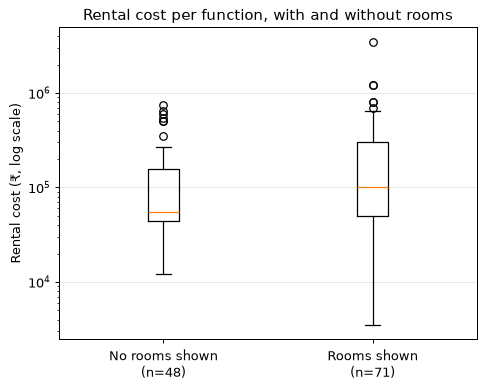

Median rental cost by capacity group (like for like):
                No rooms shown  Rooms shown
capacity_group                             
Up to 500              45000.0      50000.0
501-1000               50000.0     165000.0
1001-3000             310000.0     350000.0
Above 3000            425000.0     200000.0

INSIGHT
- Median rental cost: ₹100,000 with rooms (n=71) vs ₹55,000 without (n=48).
- That is 1.8 times. The table above shows how much of this is only because rooms-venues are bigger.


In [10]:
with_rooms = df.loc[df["has_rooms"], "rental_cost"].dropna()
no_rooms = df.loc[~df["has_rooms"], "rental_cost"].dropna()

if len(with_rooms) >= 3 and len(no_rooms) >= 3:
    plt.figure(figsize=(6, 4.5))
    plt.boxplot([no_rooms, with_rooms])
    plt.xticks([1, 2], [f"No rooms shown\n(n={len(no_rooms)})", f"Rooms shown\n(n={len(with_rooms)})"])
    plt.yscale("log")
    plt.title("Rental cost per function, with and without rooms")
    plt.ylabel("Rental cost (₹, log scale)")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

    print("Median rental cost by capacity group (like for like):")
    like = df.pivot_table(index="capacity_group", columns="has_rooms", values="rental_cost", aggfunc="median", observed=True)
    like.columns = ["Rooms shown" if bool(c) else "No rooms shown" for c in like.columns]
    print(like.round(0).to_string())

    print("\nINSIGHT")
    print(f"- Median rental cost: {rs(with_rooms.median())} with rooms (n={len(with_rooms)}) vs {rs(no_rooms.median())} without (n={len(no_rooms)}).")
    print(f"- That is {with_rooms.median() / no_rooms.median():.1f} times. The table above shows how much of this is only because rooms-venues are bigger.")
else:
    print("Too few venues in one of the groups for a fair comparison.")

**How to use this:** If rooms are included, customers should compare only with other venues that have rooms. Owners with rooms should make them clearly visible on the listing.

### Q10. Do higher-rated venues charge more?

Median rental cost by rating group:
              count    median
rating_group                 
Below 4.5        12  112500.0
4.5 to 4.9       13  270000.0
5.0              63  100000.0


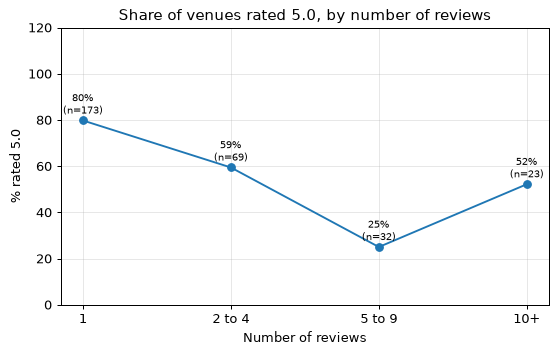

INSIGHT
- Rating vs rental cost: Spearman -0.23 (88 venues); only venues with 5+ reviews: -0.04 (20 venues).
- A value near 0 means rating does not explain price. Association only, not cause.
- Share rated 5.0: 80% for '1' review(s) vs 52% for '10+' reviews.


In [11]:
rc = df[df["rating"].notna() & df["rental_cost"].notna()]
rho_all = rc[["rating", "rental_cost"]].corr(method="spearman").iloc[0, 1] if len(rc) > 5 else float("nan")
reliable = rc[rc["enough_reviews"]]
rho_rel = reliable[["rating", "rental_cost"]].corr(method="spearman").iloc[0, 1] if len(reliable) > 5 else float("nan")

by_rating = rc.groupby("rating_group", observed=True)["rental_cost"].agg(["count", "median"]).round(0)
print("Median rental cost by rating group:")
print(by_rating.to_string())

rated_df = df[df["rating"].notna()].copy()
rated_df["is_five"] = rated_df["rating"] == 5.0
five = rated_df.groupby("review_group", observed=True)["is_five"].agg(["count", "mean"])
five = five[five["count"] > 0]
if len(five) >= 2:
    plt.figure(figsize=(7, 4))
    plt.plot(five.index.astype(str), five["mean"] * 100, marker="o")
    for x, (share, n) in enumerate(zip(five["mean"] * 100, five["count"])):
        plt.text(x, share + 3, f"{share:.0f}%\n(n={n})", ha="center", fontsize=8)
    plt.ylim(0, 120)
    plt.title("Share of venues rated 5.0, by number of reviews")
    plt.xlabel("Number of reviews")
    plt.ylabel("% rated 5.0")
    plt.grid(alpha=0.3)
    plt.show()

print("INSIGHT")
print(f"- Rating vs rental cost: Spearman {rho_all:.2f} ({len(rc)} venues); only venues with 5+ reviews: {rho_rel:.2f} ({len(reliable)} venues).")
print("- A value near 0 means rating does not explain price. Association only, not cause.")
if len(five) >= 2:
    print(f"- Share rated 5.0: {five['mean'].iloc[0]:.0%} for '{five.index[0]}' review(s) vs {five['mean'].iloc[-1]:.0%} for '{five.index[-1]}' reviews.")

**How to use this:** If the link is weak, a higher price does not guarantee a better rating, so customers should check reviews and not just price. Owners cannot rely on a rating alone to justify a higher price; more reviews make it believable.

### Q11. Are promoted venues priced or rated differently?

In [12]:
paid = df.groupby("is_paid").agg(
    venues=("venue_name", "count"),
    show_rental_cost=("has_rental_cost", "mean"),
    median_cost=("rental_cost", "median"),
    median_capacity=("capacity_max", "median"),
    avg_rating=("rating", "mean"),
    median_reviews=("reviews", "median"),
)
paid.index = ["Organic" if not i else "Promoted" for i in paid.index]
paid["show_rental_cost"] = (paid["show_rental_cost"] * 100).round(0)
print(paid.round(2).to_string())

pc = df.loc[df["is_paid"], "rental_cost"].dropna()
oc = df.loc[~df["is_paid"], "rental_cost"].dropna()
if len(pc) >= 5 and len(oc) >= 5:
    plt.figure(figsize=(6, 4.5))
    plt.boxplot([oc, pc])
    plt.xticks([1, 2], [f"Organic\n(n={len(oc)})", f"Promoted\n(n={len(pc)})"])
    plt.yscale("log")
    plt.title("Rental cost: organic vs promoted listings")
    plt.ylabel("Rental cost (₹, log scale)")
    plt.grid(axis="y", alpha=0.3)
    plt.show()
    print("INSIGHT")
    print(f"- Median rental cost: {rs(pc.median())} promoted vs {rs(oc.median())} organic.")
else:
    print("Too few promoted (or organic) venues with a rental cost for a chart.")

         venues  show_rental_cost  median_cost  median_capacity  avg_rating  median_reviews
Organic     420              28.0      94000.0            600.0        4.76             1.0
Too few promoted (or organic) venues with a rental cost for a chart.


**How to use this:** If promoted venues sit at a different price level, promoted slots shape what customers see first, which is worth checking for fairness. Owners should pay for promotion only if their price level fits the customers who see promoted listings.

### Q12. Which venue types show a flat rental cost and which show only a plate price?
Types with at least 8 venues.

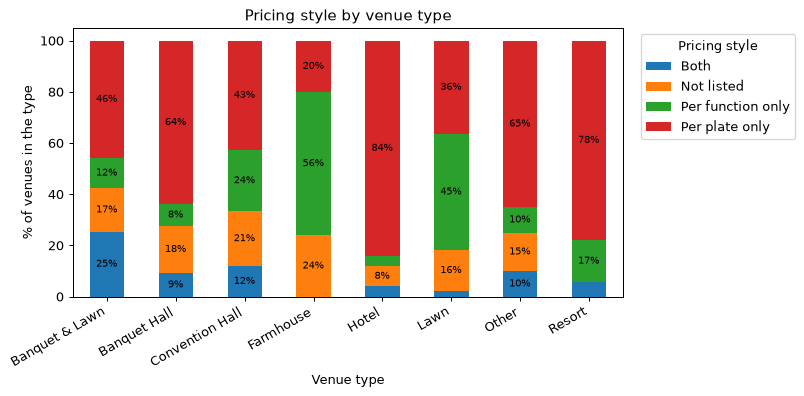

INSIGHT
- 'Farmhouse' venues most often show a rental cost (56%); 'Hotel' venues least often (8%).


In [13]:
big_types = df["venue_group"].value_counts()[lambda s: s >= 8].index
sub = df[df["venue_group"].isin(big_types)]
if len(big_types) >= 2:
    style_ct = pd.crosstab(sub["venue_group"], sub["pricing_type"], normalize="index") * 100
    ax = style_ct.plot(kind="bar", stacked=True, figsize=(9, 4.5))
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v:.0f}%" if v >= 6 else "" for v in container.datavalues], label_type="center", fontsize=8)
    plt.title("Pricing style by venue type")
    plt.xlabel("Venue type")
    plt.ylabel("% of venues in the type")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Pricing style", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
    share = sub.groupby("venue_group")["has_rental_cost"].mean().sort_values(ascending=False)
    print("INSIGHT")
    print(f"- '{share.index[0]}' venues most often show a rental cost ({share.iloc[0]:.0%}); '{share.index[-1]}' venues least often ({share.iloc[-1]:.0%}).")
else:
    print("Fewer than 2 venue types have 8 or more venues, so no chart is drawn.")

**How to use this:** For types that show only a plate price, customers should ask for the rental cost separately. For flat-price types, ask what food and decor cost on top. The platform should show both styles in one clear format.

# C. Three or more variables together

### Q13. What is a fair price for my venue type and size?
Median rental cost for each type and capacity group. A cell is blank when fewer than 3 priced venues sit in it, because a median of 1 or 2 venues is not reliable. **Owners can use this as a benchmark table.**

capacity_group   Up to 500  501-1000  1001-3000  Above 3000
venue_group                                                
Banquet & Lawn     47500.0  177500.0   270000.0    200000.0
Banquet Hall       60000.0   49000.0        NaN         NaN
Convention Hall        NaN  100000.0   490000.0         NaN
Farmhouse          47500.0       NaN        NaN         NaN
Hotel              25000.0       NaN        NaN         NaN
Lawn               35000.0  125000.0   155000.0         NaN
Other                  NaN       NaN        NaN         NaN
Resort                 NaN       NaN        NaN         NaN


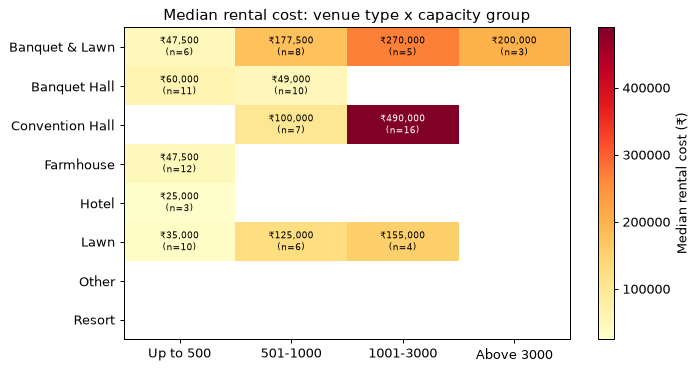

INSIGHT
- 32 type-and-size combinations have at least 3 priced venues.
- Highest: Convention Hall, capacity '1001-3000' (₹490,000). Lowest: Hotel, capacity 'Up to 500' (₹25,000).


In [14]:
price_heat = df.pivot_table(index="venue_group", columns="capacity_group", values="rental_cost", aggfunc="median", observed=True)
count_heat = df.pivot_table(index="venue_group", columns="capacity_group", values="rental_cost", aggfunc="count", observed=True)
count_heat = count_heat.reindex(index=price_heat.index, columns=price_heat.columns).fillna(0)
price_heat = price_heat.where(count_heat >= 3)
print(price_heat.round(0).to_string())

values = price_heat.values.astype(float)
if np.isfinite(values).any():
    plt.figure(figsize=(8, 4.5))
    plt.imshow(values, cmap="YlOrRd", aspect="auto")
    plt.colorbar(label="Median rental cost (₹)")
    plt.xticks(range(len(price_heat.columns)), price_heat.columns)
    plt.yticks(range(len(price_heat.index)), price_heat.index)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if np.isfinite(values[i, j]):
                dark = values[i, j] > 0.6 * np.nanmax(values)
                plt.text(j, i, f"{rs(values[i, j])}\n(n={int(count_heat.values[i, j])})", ha="center", va="center", fontsize=7,
                         color="white" if dark else "black")
    plt.title("Median rental cost: venue type x capacity group")
    plt.show()
    cells = price_heat.stack()
    print("INSIGHT")
    print(f"- {len(cells)} type-and-size combinations have at least 3 priced venues.")
    print(f"- Highest: {cells.idxmax()[0]}, capacity '{cells.idxmax()[1]}' ({rs(cells.max())}). Lowest: {cells.idxmin()[0]}, capacity '{cells.idxmin()[1]}' ({rs(cells.min())}).")
else:
    print("No type-and-size combination has 3 or more priced venues, so there is no benchmark table yet.")

**How to use this:** The fair benchmark for your price is the cell that matches your type and capacity group, not the whole market. Customers can use it the same way to check whether a quote is high or low.

### Q14. What do high-priced venues offer that cheap ones do not?
Tiers: Low, Mid and High, each holding one third of the priced venues.

             venues  median_cost  median_capacity  share_with_rooms  avg_extra_features  avg_rating  median_reviews
rental_tier                                                                                                        
Low              40      30000.0            400.0              45.0                3.45        4.85             1.0
Mid              39      94000.0            600.0              61.5                3.74        4.86             1.0
High             40     400000.0           2000.0              72.5                3.82        4.75             2.0


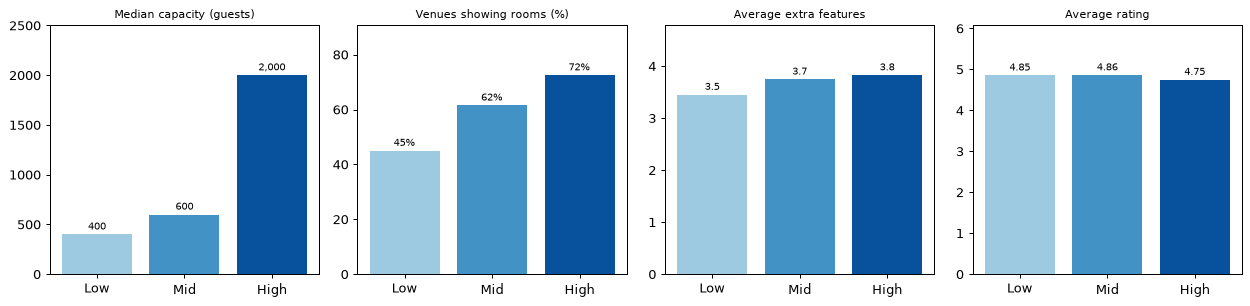

INSIGHT
- Median rental cost rises from ₹30,000 (Low) to ₹400,000 (High).
- Capacity: 2,000 guests in High vs 400 in Low.
- Rooms shown: 72% in High vs 45% in Low.
- Extra features: 3.8 vs 3.5. Average rating: 4.75 vs 4.85.


In [15]:
tier = df.groupby("rental_tier", observed=True).agg(
    venues=("venue_name", "count"),
    median_cost=("rental_cost", "median"),
    median_capacity=("capacity_max", "median"),
    share_with_rooms=("has_rooms", "mean"),
    avg_extra_features=("extra_features", "mean"),
    avg_rating=("rating", "mean"),
    median_reviews=("reviews", "median"),
)
tier["share_with_rooms"] = (tier["share_with_rooms"] * 100).round(1)
print(tier.round(2).to_string())

if len(tier) == 3:
    metrics = [("median_capacity", "Median capacity (guests)", "{:,.0f}"), ("share_with_rooms", "Venues showing rooms (%)", "{:.0f}%"),
               ("avg_extra_features", "Average extra features", "{:.1f}"), ("avg_rating", "Average rating", "{:.2f}")]
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
    for ax, (col, title, fmt) in zip(axes, metrics):
        vals = tier[col].fillna(0)
        bars = ax.bar(tier.index.astype(str), vals, color=["#9ecae1", "#4292c6", "#08519c"])
        ax.bar_label(bars, labels=[fmt.format(v) for v in vals], padding=2, fontsize=8)
        ax.set_title(title, fontsize=9)
        ax.set_ylim(0, max(vals.max() * 1.25, 0.1))
    plt.tight_layout()
    plt.show()
    low, high = tier.loc["Low"], tier.loc["High"]
    print("INSIGHT")
    print(f"- Median rental cost rises from {rs(low.median_cost)} (Low) to {rs(high.median_cost)} (High).")
    print(f"- Capacity: {high.median_capacity:,.0f} guests in High vs {low.median_capacity:,.0f} in Low.")
    print(f"- Rooms shown: {high.share_with_rooms:.0f}% in High vs {low.share_with_rooms:.0f}% in Low.")
    print(f"- Extra features: {high.avg_extra_features:.1f} vs {low.avg_extra_features:.1f}. Average rating: {high.avg_rating:.2f} vs {low.avg_rating:.2f}.")

**How to use this:** The things that clearly differ between High and Low tiers are what owners should highlight when positioning as premium. A feature that does not differ will not support a higher price.

### Q15. Where is supply thin?
Number of venues for every price tier and size combination. Small numbers mean customers in that segment have few choices.

capacity_group  Up to 500  501-1000  1001-3000  Above 3000
rental_tier                                               
Low                    26        12          1           1
Mid                    16        14          7           2
High                    2         9         21           7


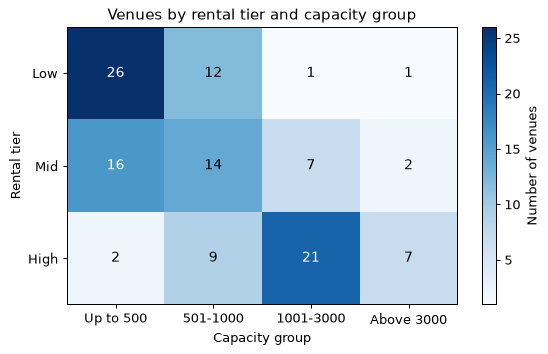

INSIGHT
- Thinnest segment: 'Low' rental cost with capacity '1001-3000' (1 venues).
- Fullest segment: 'Low' rental cost with capacity 'Up to 500' (26 venues).


In [16]:
segment = pd.crosstab(df["rental_tier"], df["capacity_group"])
segment = segment.reindex(index=ORDER["rental_tier"], columns=ORDER["capacity_group"]).fillna(0).astype(int)
print(segment.to_string())

plt.figure(figsize=(7, 4))
plt.imshow(segment.values, cmap="Blues", aspect="auto")
plt.colorbar(label="Number of venues")
plt.xticks(range(segment.shape[1]), segment.columns)
plt.yticks(range(segment.shape[0]), segment.index)
for i in range(segment.shape[0]):
    for j in range(segment.shape[1]):
        plt.text(j, i, int(segment.values[i, j]), ha="center", va="center", fontsize=11,
                 color="white" if segment.values[i, j] > 0.6 * segment.values.max() else "black")
plt.title("Venues by rental tier and capacity group")
plt.xlabel("Capacity group")
plt.ylabel("Rental tier")
plt.show()

stacked = segment.stack()
print("INSIGHT")
print(f"- Thinnest segment: '{stacked.idxmin()[0]}' rental cost with capacity '{stacked.idxmin()[1]}' ({stacked.min()} venues).")
print(f"- Fullest segment: '{stacked.idxmax()[0]}' rental cost with capacity '{stacked.idxmax()[1]}' ({stacked.max()} venues).")

**How to use this:** Customers whose budget and guest count fall in a thin segment should start early. The platform can look for new venues there, after checking that customers really search for them. An owner may find an opening in a thin segment with demand.

### Q16. Which venues look like good value?
A simple shortlist, not a score. A venue is a **value pick** if it:
1. charges at or below the median rental cost of its own venue type,
2. has a rating of 4.5 or more with at least 5 reviews,
3. holds at least the typical capacity of all venues.

Value picks: 6 out of 119 venues with a rental cost

                                              venue_name     venue_group       area  rental_cost  cost_vs_type_median  rating  reviews  capacity_max  rooms
                                        Celebrity Resort          Resort  Shamirpet      30000.0                 0.16     5.0       17        5000.0   75.0
                                         Rainbow Retreat Convention Hall   Moinabad      55000.0                 0.16     4.9        5        1000.0    7.0
                                       The Amaltaas Fort           Other   Moinabad     100000.0                 0.50     5.0       69        2500.0   10.0
                                 Advaya Lawns & Banquets  Banquet & Lawn        NaN     100000.0                 0.62     5.0        9        2000.0   10.0
Maruti Garden | Shree Maruti Kalyana Mandapam - Pure Veg           Other Lakdikapul     200000.0                 1.00     4.5       21        1000.0   30.0
           

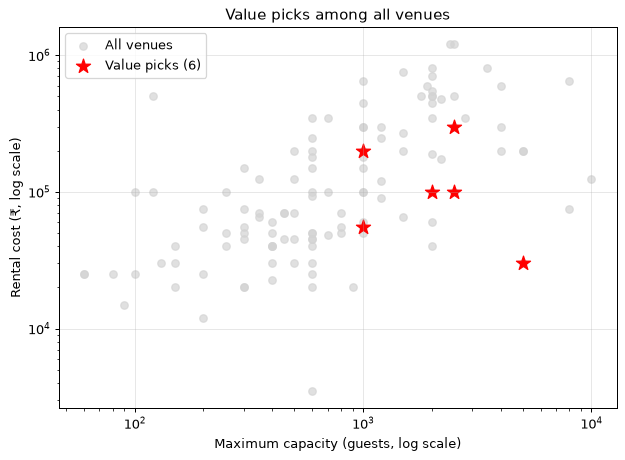


INSIGHT
- Median rental cost of value picks: ₹100,000 vs ₹94,000 for all venues.
- By type: Other (2), Convention Hall (2), Resort (1), Banquet & Lawn (1).
- Only 13% of all venues have 5 or more reviews, which is why the list is short.
- This uses listing information only. It ignores food quality, decor, parking, dates and exact location.


In [17]:
type_median = df.groupby("venue_group")["rental_cost"].transform("median")
df["cost_vs_type_median"] = df["rental_cost"] / type_median

value_picks = df[
    (df["cost_vs_type_median"] <= 1)
    & (df["rating"] >= 4.5)
    & (df["reviews"] >= 5)
    & (df["capacity_max"] >= df["capacity_max"].median())
]
print(f"Value picks: {len(value_picks)} out of {int(df['rental_cost'].notna().sum())} venues with a rental cost\n")
if len(value_picks) > 0:
    show = ["venue_name", "venue_group", "area", "rental_cost", "cost_vs_type_median", "rating", "reviews", "capacity_max", "rooms"]
    print(value_picks[show].sort_values("rental_cost").head(15).round(2).to_string(index=False))

    plt.figure(figsize=(8, 5.5))
    plt.scatter(df["capacity_max"], df["rental_cost"], color="lightgrey", alpha=0.7, label="All venues")
    plt.scatter(value_picks["capacity_max"], value_picks["rental_cost"], color="red", marker="*", s=140, label=f"Value picks ({len(value_picks)})")
    plt.xscale("log")
    plt.yscale("log")
    plt.title("Value picks among all venues")
    plt.xlabel("Maximum capacity (guests, log scale)")
    plt.ylabel("Rental cost (₹, log scale)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    print("\nINSIGHT")
    print(f"- Median rental cost of value picks: {rs(value_picks['rental_cost'].median())} vs {rs(df['rental_cost'].median())} for all venues.")
    print(f"- By type: {', '.join(f'{k} ({v})' for k, v in value_picks['venue_group'].value_counts().items())}.")
else:
    print("No venue passes all three rules. The review rule is usually the strictest.")
print(f"- Only {df['enough_reviews'].mean():.0%} of all venues have 5 or more reviews, which is why the list is short.")
print("- This uses listing information only. It ignores food quality, decor, parking, dates and exact location.")

**How to use this:** Customers can use the list to start a shortlist, then visit and ask for a full quote with food and decor. The platform could build a "good value" filter, which only works if more venues collect reviews.

### Bonus: which numbers move together?
Spearman correlation (works for skewed data). Correlation means two columns move together, not that one causes the other.

                rental_cost  veg_price  capacity_max  rooms  rating  reviews  extra_features
rental_cost            1.00       0.39          0.64   0.09   -0.23     0.33            0.19
veg_price              0.39       1.00          0.16   0.25   -0.13     0.36            0.46
capacity_max           0.64       0.16          1.00   0.06   -0.11     0.34            0.12
rooms                  0.09       0.25          0.06   1.00   -0.01     0.18           -0.36
rating                -0.23      -0.13         -0.11  -0.01    1.00    -0.27            0.03
reviews                0.33       0.36          0.34   0.18   -0.27     1.00            0.22
extra_features         0.19       0.46          0.12  -0.36    0.03     0.22            1.00


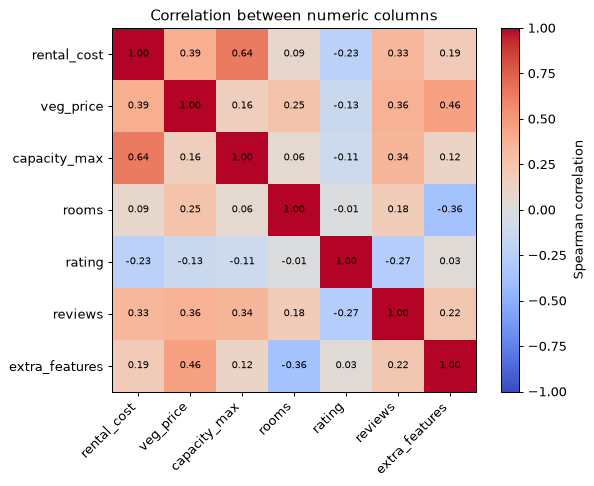

INSIGHT: link with rental cost
- rental_cost and veg_price: 0.39
- rental_cost and capacity_max: 0.64
- rental_cost and rooms: 0.09
- rental_cost and rating: -0.23
- rental_cost and reviews: 0.33
- rental_cost and extra_features: 0.19

Part 3 is done. Close this notebook and open Part 4.


In [18]:
num_cols = ["rental_cost", "veg_price", "capacity_max", "rooms", "rating", "reviews", "extra_features"]
corr = df[num_cols].corr(method="spearman").round(2)
print(corr.to_string())

plt.figure(figsize=(7, 5.5))
plt.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
plt.yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        v = corr.values[i, j]
        plt.text(j, i, "" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation between numeric columns")
plt.tight_layout()
plt.show()

print("INSIGHT: link with rental cost")
for col in num_cols[1:]:
    print(f"- rental_cost and {col}: {corr.loc['rental_cost', col]}")
print("\nPart 3 is done. Close this notebook and open Part 4.")